In [ ]:
import pandas as pd
import pandas as pd
from tqdm import tqdm
from openai import OpenAI
import pickle


#Read Data

In [ ]:
output_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/final_Type_jugment.xlsx"
df = pd.read_excel(output_file)
with open("/content/drive/MyDrive/fix_systematic_review/134_texts.pkl", "rb") as f:
    file_texts = pickle.load(f)


#Get country

In [ ]:
prompt_template = """
You are an expert in systematic reviews.
Your task is to identify the country where the study was conducted, if mentioned.

Input:
Title: {title}
Text: {text}

Respond in the exact format:
Country: <country name or None>
"""


In [ ]:
import pandas as pd
import re
from openai import OpenAI

client = OpenAI(api_key="api_key")



def call_openai(prompt, model="gpt-4o-mini"):
    try:
        response = client.chat.completions.create(
            model=model,
            messages=[{"role": "user", "content": prompt}],
         temperature=0,
    max_tokens=2048,
    top_p=0.45
        )
        return response.choices[0].message.content.strip()
    except Exception as e:
        return f"Error: {e}"




In [ ]:
from tqdm import tqdm
import time

# Column names
type_col = "Type_final"               # Column with MMAT type (e.g., "Qualitative", "Mixed methods")
text_col = "Matching_Filename"  # Column with the filename to get text from

# Save settings
save_interval = 10              # Save progress every N rows
output_file = "/content/drive/MyDrive/fix_systematic_review/location_participants/country_gpt.xlsx"  # Path to save progress file

df[f"country"] = ""

start_time = time.time()

# Loop over DataFrame rows with tqdm progress bar
for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):
    title = row.get('Title', None)       # Get MMAT type for this row
    number_id = row.get(text_col, None) # Get filename for this row


    prompt = prompt_template.format(text=file_texts[number_id],title= title)
    # Send prompt to the model and get the result
    result = call_openai(prompt)
    # print( result)

    # Save the result in the corresponding MMAT_Q column
    df.at[i, f"country"] = result

    # Save progress every 'save_interval' rows
    if i % save_interval == 0 and i > 0:
        df.to_excel(output_file, index=False)
        print(f"💾 Progress saved at row {i} to {output_file}")
# Final save after processing all rows
df.to_excel(output_file, index=False)
print(f"✅ Processing completed. Final file saved to {output_file}")


In [ ]:
import re

df['country_extracted'] = df['country'].str.extract(r'Country:\s*(.*)')


#Normalize country

In [ ]:
promt_to_fix = """You are given a text field that contains information about the countries in which a study was conducted.
The field may contain a single country, multiple countries separated by commas, or descriptive text with comparisons and synonyms (e.g., "USA", "United States of America", "England/UK", or "England/UK/United States (multiple countries mentioned...)").

The text:{text}
Your task is:
1. Extract all the country names mentioned in the text.
2. Normalize them into a consistent, standardized English form (e.g., "USA" → "United States", "United States of America" → "United States", "England/UK" → "United Kingdom").
3. Return the result as a JSON array of country names, without duplicates.
4. Do not include any explanations, only the clean JSON list.

Examples:

Input: "Country: USA"
Output: ["United States"]

Input: "England/UK/United States (multiple countries mentioned, but the study was conducted in the UK, with comparisons to the USA)"
Output: ["United Kingdom", "United States"]

Input: "Australia, Canada, Finland, Greece, Ireland, Norway, Sweden, United Kingdom, United States"
Output: ["Australia", "Canada", "Finland", "Greece", "Ireland", "Norway", "Sweden", "United Kingdom", "United States"]

Input: "United States, Saudi Arabia"
Output: ["United States", "Saudi Arabia"]

Input: "Hong Kong, China"
Output: ["Hong Kong", "China"]

output:[]
"""

In [ ]:
from tqdm import tqdm
import time

# Column names
type_col = "Type_final"               # Column with MMAT type (e.g., "Qualitative", "Mixed methods")
text_col = "Matching_Filename"  # Column with the filename to get text from

# Save settings
save_interval = 10              # Save progress every N rows

df[f"country_fix"] = ""

start_time = time.time()

# Loop over DataFrame rows with tqdm progress bar
for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):
    text = row.get('country_extracted', None)       # Get MMAT type for this row


    prompt = promt_to_fix.format(text=text)
    # Send prompt to the model and get the result
    result = call_openai(prompt)
    # print( result)

    # Save the result in the corresponding MMAT_Q column
    df.at[i, f"country_fix"] = result

    # Save progress every 'save_interval' rows
    if i % save_interval == 0 and i > 0:
        df.to_excel(output_file, index=False)
        print(f"💾 Progress saved at row {i} to {output_file}")
# Final save after processing all rows
df.to_excel(output_file, index=False)
print(f"✅ Processing completed. Final file saved to {output_file}")


In [ ]:
import ast
import re

def clean_and_parse(x):
    if isinstance(x, str):
        x = x.replace("```json", "").replace("```", "").replace("``", "").replace("`", "").strip()
        if re.match(r'^\[.*\]$', x):
            try:
                val = ast.literal_eval(x)
                if isinstance(val, list) and len(val) == 1 and isinstance(val[0], str) and val[0].startswith('['):
                    try:
                        return ast.literal_eval(val[0])
                    except Exception:
                        return val
                return val
            except Exception:
                return [x]
        return [x]
    return x


df['country_fix'] = df['country_fix'].apply(lambda s:str(s))
df['country_fix'] = df['country_fix'].apply(clean_and_parse)
df_exploded = df.explode('country_fix')

country_counts = df_exploded['country_fix'].value_counts()
print(country_counts)


country_fix
United States           31
United Kingdom          18
Australia               12
Saudi Arabia             6
China                    5
Canada                   5
Turkey                   5
Iran                     3
Norway                   3
Ireland                  3
Taiwan                   3
Hong Kong                2
Sweden                   2
Denmark                  2
Spain                    2
Ethiopia                 2
South Africa             2
Netherlands              2
Colombia                 1
Ghana                    1
Nepal                    1
Jordan                   1
South Korea              1
United Arab Emirates     1
Bolivia                  1
Jamaica                  1
Austria                  1
Singapore                1
Kenya                    1
Nigeria                  1
Finland                  1
Malaysia                 1
Chile                    1
Tunisia                  1
Name: count, dtype: int64


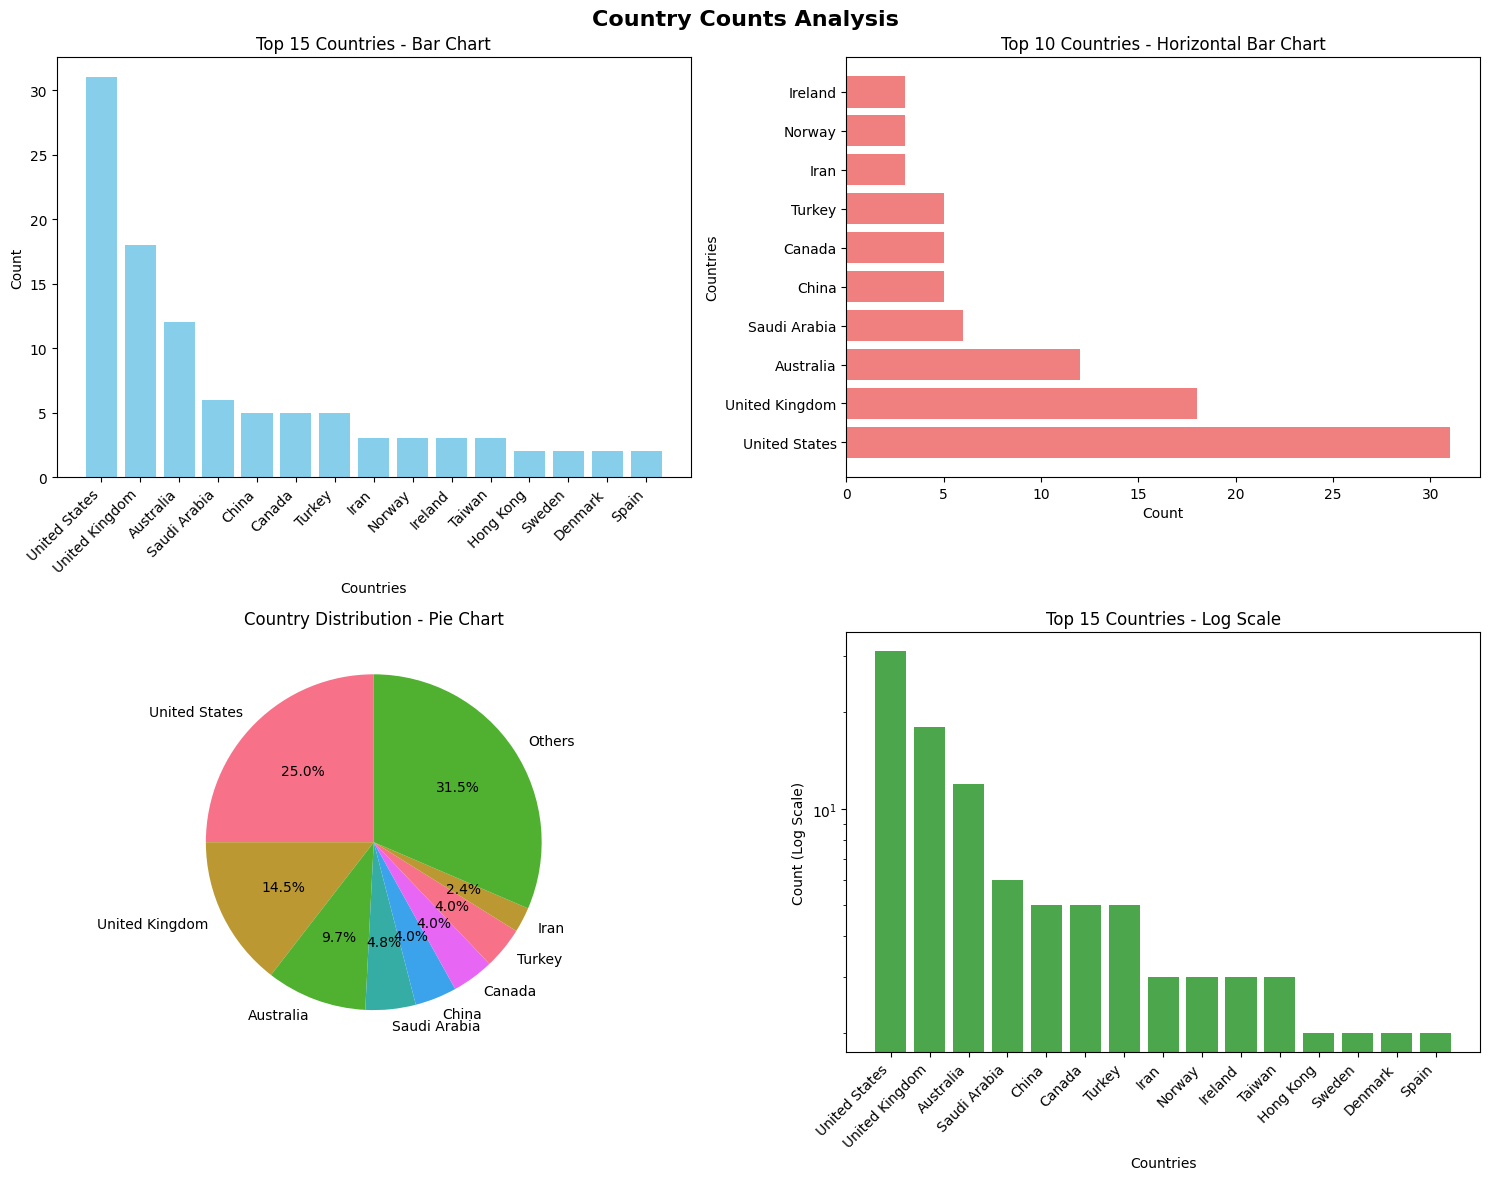

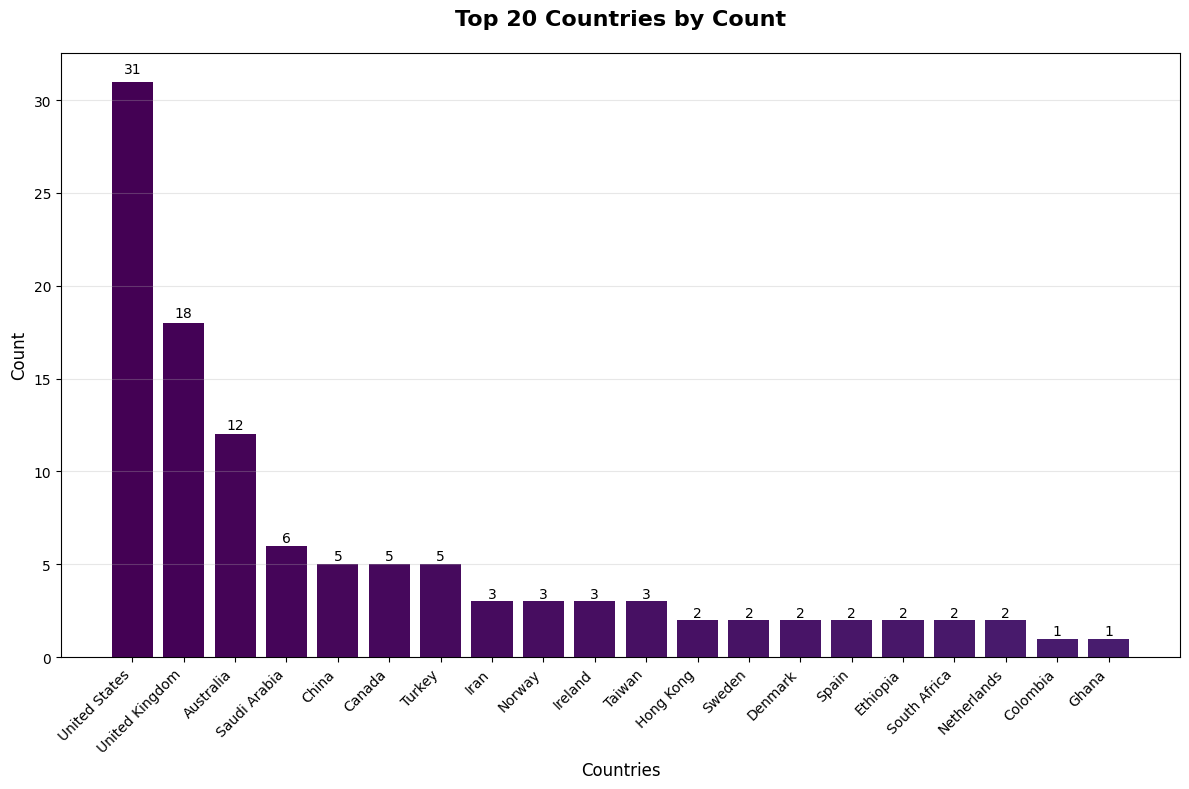

=== Country Counts Statistics ===
Total unique countries: 34
Total count: 124
Most common country: United States (31 occurrences)
Least common countries: 16 countries with 1 occurrence

Top 10 Countries:
country_fix
United States     31
United Kingdom    18
Australia         12
Saudi Arabia       6
China              5
Canada             5
Turkey             5
Iran               3
Norway             3
Ireland            3


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd



plt.style.use('default')
sns.set_palette("husl")

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Country Counts Analysis', fontsize=16, fontweight='bold')

# 1. Bar Chart - Top 15 countries
top_countries = country_counts.head(15)
axes[0, 0].bar(range(len(top_countries)), top_countries.values, color='skyblue')
axes[0, 0].set_title('Top 15 Countries - Bar Chart')
axes[0, 0].set_xlabel('Countries')
axes[0, 0].set_ylabel('Count')
axes[0, 0].set_xticks(range(len(top_countries)))
axes[0, 0].set_xticklabels(top_countries.index, rotation=45, ha='right')

# 2. Horizontal Bar Chart - Top 10
top_10 = country_counts.head(10)
axes[0, 1].barh(range(len(top_10)), top_10.values, color='lightcoral')
axes[0, 1].set_title('Top 10 Countries - Horizontal Bar Chart')
axes[0, 1].set_xlabel('Count')
axes[0, 1].set_ylabel('Countries')
axes[0, 1].set_yticks(range(len(top_10)))
axes[0, 1].set_yticklabels(top_10.index)

# 3. Pie Chart - Top 8 + Others
top_8 = country_counts.head(8)
others_count = country_counts.iloc[8:].sum()
pie_data = list(top_8.values) + [others_count]
pie_labels = list(top_8.index) + ['Others']

axes[1, 0].pie(pie_data, labels=pie_labels, autopct='%1.1f%%', startangle=90)
axes[1, 0].set_title('Country Distribution - Pie Chart')

# 4. Log scale bar chart (for better visibility of smaller values)
axes[1, 1].bar(range(len(top_countries)), top_countries.values, color='green', alpha=0.7)
axes[1, 1].set_title('Top 15 Countries - Log Scale')
axes[1, 1].set_xlabel('Countries')
axes[1, 1].set_ylabel('Count (Log Scale)')
axes[1, 1].set_yscale('log')
axes[1, 1].set_xticks(range(len(top_countries)))
axes[1, 1].set_xticklabels(top_countries.index, rotation=45, ha='right')

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
top_20 = country_counts.head(20)

colors = plt.cm.viridis(range(len(top_20)))

bars = plt.bar(range(len(top_20)), top_20.values, color=colors)
plt.title('Top 20 Countries by Count', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Countries', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(range(len(top_20)), top_20.index, rotation=45, ha='right')

for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + height*0.01,
             f'{int(height)}', ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("=== Country Counts Statistics ===")
print(f"Total unique countries: {len(country_counts)}")
print(f"Total count: {country_counts.sum()}")
print(f"Most common country: {country_counts.index[0]} ({country_counts.iloc[0]} occurrences)")
print(f"Least common countries: {country_counts[country_counts == 1].shape[0]} countries with 1 occurrence")

print("\nTop 10 Countries:")
print(country_counts.head(10).to_string())



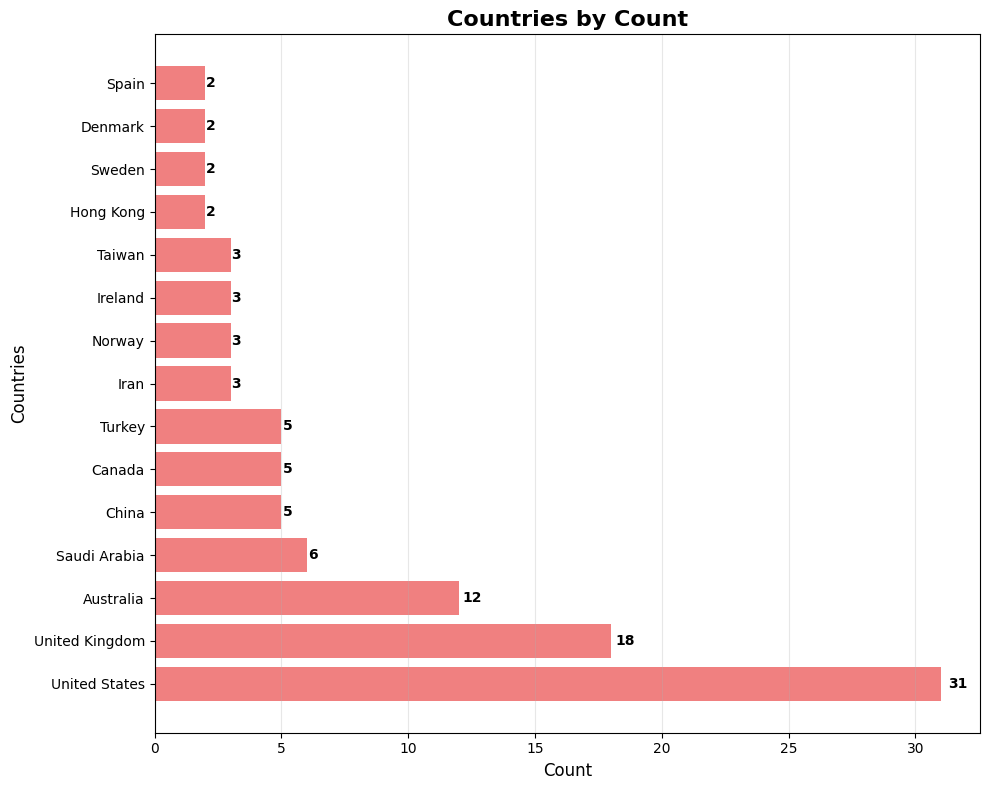

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# country_counts = df_exploded['country_fix'].value_counts()

top_countries = country_counts.head(15)

plt.figure(figsize=(10, 8))

bars = plt.barh(range(len(top_countries)), top_countries.values, color='lightcoral')

plt.title('Countries by Count', fontsize=16, fontweight='bold')
plt.xlabel('Count', fontsize=12)
plt.ylabel('Countries', fontsize=12)
plt.yticks(range(len(top_countries)), top_countries.index)

for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width + width*0.01, bar.get_y() + bar.get_height()/2,
             f'{int(width)}', ha='left', va='center', fontsize=10, fontweight='bold')

plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

#Extract participants

In [ ]:
prompt_template = """
You are an expert in systematic reviews.
Your task is to identify how many participants actually took part in the study.

Important:
- Extract only the final number of participants who actually participated in the study.
- If both invited and responded numbers are given, select the responded (completed) number.
- If ranges or multiple numbers are mentioned, choose the one that clearly represents the actual participants included in the analysis.
- If no participant number is explicitly stated, respond with None.

Input:
Title: {title}
Text: {text}

Respond in the exact format:
Participants_actual: <number or None>
"""


In [ ]:
from tqdm import tqdm
import time

# Column names
type_col = "Type_final"               # Column with MMAT type (e.g., "Qualitative", "Mixed methods")
text_col = "Matching_Filename"  # Column with the filename to get text from

# Save settings
save_interval = 10              # Save progress every N rows
output_file = "/content/drive/MyDrive/fix_systematic_review/location_participants/participants_gpt.xlsx"  # Path to save progress file

df[f"participants"] = ""

start_time = time.time()

# Loop over DataFrame rows with tqdm progress bar
for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):
    title = row.get('Title', None)       # Get MMAT type for this row
    number_id = row.get(text_col, None) # Get filename for this row

    prompt = prompt_template.format(text=file_texts[number_id],title= title)
    # Send prompt to the model and get the result
    result = call_openai(prompt)
    # print( result)

    # Save the result in the corresponding MMAT_Q column
    df.at[i, f"participants"] = result

    # Save progress every 'save_interval' rows
    if i % save_interval == 0 and i > 0:
        df.to_excel(output_file, index=False)
        print(f"💾 Progress saved at row {i} to {output_file}")
# Final save after processing all rows
df.to_excel(output_file, index=False)
print(f"✅ Processing completed. Final file saved to {output_file}")


In [ ]:
import pandas as pd


output_file = "/content/drive/MyDrive/fix_systematic_review/location_participants/participants_gpt.xlsx"  # Path to save progress file
df = pd.read_excel(output_file)

In [ ]:
import ast
import re

def clean_and_parse(x):
    if isinstance(x, str):
        x = x.replace("```json", "").replace("```", "").replace("``", "").replace("`", "").strip()
        if re.match(r'^\[.*\]$', x):
            try:
                val = ast.literal_eval(x)
                if isinstance(val, list) and len(val) == 1 and isinstance(val[0], str) and val[0].startswith('['):
                    try:
                        return ast.literal_eval(val[0])
                    except Exception:
                        return val
                return val
            except Exception:
                return [x]
        return [x]
    return x


df['country_fix'] = df['country_fix'].apply(lambda s:str(s))
df['country_fix'] = df['country_fix'].apply(clean_and_parse)


In [ ]:
import re
pattern = r"Participants_actual:\s*([\d,]+)"

def extract_participants(lst):
    results = []
    for t in lst:
        match = re.search(pattern, t)
        if match:
            num = int(match.group(1).replace(",", ""))
            results.append(num)
        else:
            results.append(None)
    return results

participants_clean = extract_participants(df.participants.tolist())


In [ ]:
df['Participants_extracted'] = participants_clean

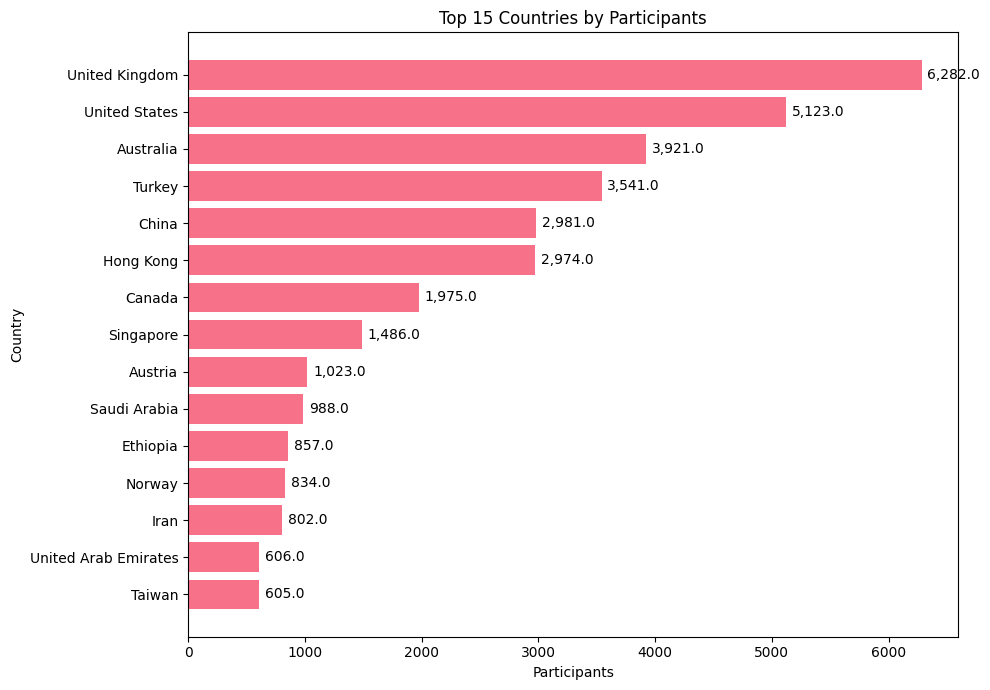

In [ ]:
import matplotlib.pyplot as plt

df_exploded = df.copy()
df_exploded = df_exploded.explode("country_fix")

# Group by country and sum participants
grouped = df_exploded.groupby("country_fix")["Participants_extracted"].sum().reset_index()

# Sort and take top 15
grouped_sorted = grouped.sort_values(by="Participants_extracted", ascending=False).head(15)

plt.figure(figsize=(10, 7))
bars = plt.barh(grouped_sorted["country_fix"], grouped_sorted["Participants_extracted"])
plt.title("Top 15 Countries by Participants")
plt.xlabel("Participants")
plt.ylabel("Country")
plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()
    plt.text(width + 50,
             bar.get_y() + bar.get_height()/2,
             f"{width:,}",
             va="center")

plt.tight_layout()
plt.show()


In [ ]:
grouped_all = (
    df_exploded.groupby("country_fix")["Participants_extracted"]
    .sum()
    .reset_index()
    .sort_values(by="Participants_extracted", ascending=False)
)

print(grouped_all.to_string(index=False))

         country_fix  Participants_extracted
      United Kingdom                  6282.0
       United States                  5123.0
           Australia                  3921.0
              Turkey                  3541.0
               China                  2981.0
           Hong Kong                  2974.0
              Canada                  1975.0
           Singapore                  1486.0
             Austria                  1023.0
        Saudi Arabia                   988.0
            Ethiopia                   857.0
              Norway                   834.0
                Iran                   802.0
United Arab Emirates                   606.0
              Taiwan                   605.0
              Sweden                   570.0
         South Korea                   409.0
             Finland                   400.0
            Malaysia                   300.0
              Jordan                   200.0
             Ireland                   199.0
          

In [ ]:
cols = ['PubMed ID', 'DOI', 'Title', 'Abstract','country', 'participants' ]

In [ ]:
df[cols].sample(20).to_excel('/content/drive/MyDrive/fix_systematic_review/location_participants/20_sample.xlsx')